# Números complexos
Neste Notebook trabalharemos sobre a noção de número complexo e sua representação no plano
1. Complexos
2. Magnitude e fase
3. Gráfico

In [35]:
import numpy as np
import matplotlib.pyplot as plt

In [36]:
# Numero complexo - Forma cartesiana
a  = 3.0 # real
b  = 4.0 # imaginaria
z1 = a + b*1j

In [37]:
print(type(a), type(b), type(z1))

<class 'float'> <class 'float'> <class 'complex'>


In [38]:
# Numero complexo - Forma polar
magnitude = np.abs(z1)   # mag. de z1
phase     = np.angle(z1) # fase de z1 (rad)

In [39]:
print(magnitude, phase)

5.0 0.9272952180016122


In [40]:
def COMPLEXmagnitude(z, version=1):
    if version == 1:
        'Pythagoras'
        return np.sqrt(z.real**2 + z.imag**2)
    if version == 2:
        'abs value'
        return np.abs(z)

In [41]:
print(COMPLEXmagnitude(z1, 1), COMPLEXmagnitude(z1, 2))

5.0 5.0


## Desafio
Crie funções customizadas para calcular o módulo e fase de um complexo.

Obs: ñ funções prontas!

In [42]:
def COMPLEXphase(z, version=3, degUnits=False):
    if version == 1:
        'arctan'
        phi = np.arctan(z.imag / z.real) # so enxerga o 1o e o 4o quadrantes!
    if version == 2:
        'arctan2'
        phi = np.arctan2(z.imag, z.real) # ordem: (Y, X)
    if version == 3:
        'angle'
        phi = np.angle(z)
        
    if degUnits:
        'rad to deg'
        phi *= 180 / np.pi
    
    return phi

In [43]:
print(COMPLEXphase(-3 -4j))

-2.214297435588181


In [44]:
# version=3 (angle), degUnits=True
COMPLEXphase( 3 + 4j, degUnits=True)

np.float64(53.13010235415598)

### As três versões concordam?

O `arctan` recebe só a razão $b/a$, então perde o sinal de cada componente: $\frac{-4}{-3} = \frac{4}{3}$.
Por isso ele confunde o 3º quadrante com o 1º (e o 2º com o 4º). O `arctan2(b, a)` recebe as duas componentes
separadas e devolve o ângulo correto em $(-\pi, \pi]$, igual ao `angle`.

In [45]:
for z in [3 + 4j, -3 + 4j, -3 - 4j, 3 - 4j]:
    print(f"z = {z!s:>8}  |z| = {COMPLEXmagnitude(z):.1f}  "
          f"arctan = {COMPLEXphase(z, 1, True):8.2f}°  "
          f"arctan2 = {COMPLEXphase(z, 2, True):8.2f}°  "
          f"angle = {COMPLEXphase(z, 3, True):8.2f}°")

z =   (3+4j)  |z| = 5.0  arctan =    53.13°  arctan2 =    53.13°  angle =    53.13°
z =  (-3+4j)  |z| = 5.0  arctan =   -53.13°  arctan2 =   126.87°  angle =   126.87°
z =  (-3-4j)  |z| = 5.0  arctan =    53.13°  arctan2 =  -126.87°  angle =  -126.87°
z =   (3-4j)  |z| = 5.0  arctan =   -53.13°  arctan2 =   -53.13°  angle =   -53.13°


## Solução do desafio — sem funções prontas

Só operadores (`+ - * / **`) e comparações; nada de `np.abs`, `np.sqrt`, `np.arctan`, `np.arctan2`, `np.angle`
e nem mesmo `np.pi`.

1. **Módulo** — Pitágoras: $|z| = (a^2 + b^2)^{1/2}$.
2. **arctan** — série de Taylor $\arctan u = u - \frac{u^3}{3} + \frac{u^5}{5} - \dots$, que só converge bem para
   $|u|$ pequeno. Duas reduções levam qualquer $u$ para perto de zero:
   - se $|u| > 1$: $\arctan u = \pm\frac{\pi}{2} - \arctan\frac{1}{u}$
   - meio ângulo: $\arctan u = 2\arctan\dfrac{u}{1 + \sqrt{1 + u^2}}$
3. **π** — sai do próprio arctan, pela fórmula de Machin: $\pi = 16\arctan\frac{1}{5} - 4\arctan\frac{1}{239}$.
4. **Fase** — um `arctan2` próprio: corrige o quadrante olhando os sinais de $a$ e $b$ separadamente
   (exatamente o que faltava à versão 1).

In [46]:
def mySeriesArctan(u, tol=1e-17):
    'arctan(u) pela serie de Taylor (|u| pequeno)'
    total, term, m = 0.0, u, 1
    while abs(term) / m > tol:   # abs() do Python so tira o sinal do termo de parada
        total += term / m
        term  *= -u * u
        m     += 2
    return total

# pi pela formula de Machin, usando so a serie acima
MY_PI = 16 * mySeriesArctan(1/5) - 4 * mySeriesArctan(1/239)

def myArctan(u):
    'arctan(u) para qualquer u real'
    if u > 1:
        return  MY_PI / 2 - myArctan(1 / u)
    if u < -1:
        return -MY_PI / 2 - myArctan(1 / u)
    for _ in range(3):           # 3 meios-angulos: |u| <= 1 -> |u| <= 0.1
        u = u / (1 + (1 + u * u) ** 0.5)
    return 8 * mySeriesArctan(u) # 2^3 = 8

def myArctan2(b, a):
    'angulo de (a, b) em (-pi, pi], decidindo o quadrante pelos sinais'
    if a > 0:
        return myArctan(b / a)                # quadrantes 1 e 4
    if a < 0:
        if b >= 0:
            return myArctan(b / a) + MY_PI    # quadrante 2
        return myArctan(b / a) - MY_PI        # quadrante 3
    if b > 0:
        return  MY_PI / 2                     # eixo imaginario +
    if b < 0:
        return -MY_PI / 2                     # eixo imaginario -
    return 0.0                                # z = 0: fase indefinida, convencao 0

def myMagnitude(z):
    return (z.real**2 + z.imag**2) ** 0.5

def myPhase(z, degUnits=False):
    phi = myArctan2(z.imag, z.real)
    if degUnits:
        phi = phi * 180 / MY_PI
    return phi

print(f"MY_PI  = {MY_PI!r}")
print(f"np.pi  = {np.pi!r}")

MY_PI  = 3.141592653589794
np.pi  = 3.141592653589793


In [47]:
for z in [3 + 4j, -3 + 4j, -3 - 4j, 3 - 4j, 1j, -1j, -1 + 0j, 0j]:
    print(f"z = {z!s:>8}  |z| = {myMagnitude(z):.4f}  fase = {myPhase(z, True):9.4f}°   "
          f"(numpy: {np.abs(z):.4f}, {np.angle(z, deg=True):9.4f}°)")

z =   (3+4j)  |z| = 5.0000  fase =   53.1301°   (numpy: 5.0000,   53.1301°)
z =  (-3+4j)  |z| = 5.0000  fase =  126.8699°   (numpy: 5.0000,  126.8699°)
z =  (-3-4j)  |z| = 5.0000  fase = -126.8699°   (numpy: 5.0000, -126.8699°)
z =   (3-4j)  |z| = 5.0000  fase =  -53.1301°   (numpy: 5.0000,  -53.1301°)
z =       1j  |z| = 1.0000  fase =   90.0000°   (numpy: 1.0000,   90.0000°)
z =  (-0-1j)  |z| = 1.0000  fase =  -90.0000°   (numpy: 1.0000,  -90.0000°)
z =  (-1+0j)  |z| = 1.0000  fase =  180.0000°   (numpy: 1.0000,  180.0000°)
z =       0j  |z| = 0.0000  fase =    0.0000°   (numpy: 0.0000,    0.0000°)


In [48]:
# Conferencia em massa: 100 mil complexos aleatorios em todos os quadrantes e escalas
rng = np.random.default_rng(0)
Z = (rng.standard_normal(100_000) + 1j * rng.standard_normal(100_000)) * 10.0 ** rng.uniform(-6, 6, 100_000)

err_mag = max(abs(myMagnitude(z) - np.abs(z)) / np.abs(z) for z in Z)
err_pha = max(abs(myPhase(z) - np.angle(z)) for z in Z)
print(f"erro relativo max do modulo: {err_mag:.1e}")
print(f"erro absoluto max da fase  : {err_pha:.1e} rad")

erro relativo max do modulo: 3.8e-16
erro absoluto max da fase  : 1.3e-15 rad


# Gráfica dos números complexos

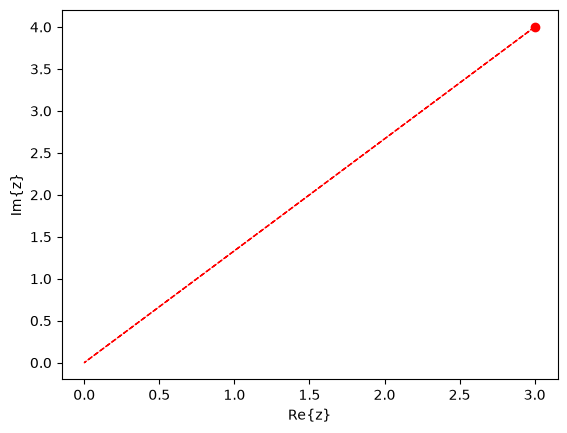

In [49]:
# Diagrama no plano complexo
x = z1.real # real
y = z1.imag # imag

# Plot
fig, ax = plt.subplots()
ax.plot(x, y, 'ro')
ax.arrow(0, 0, x, y, color='r', linestyle='--')
ax.set_xlabel('Re{z}')
ax.set_ylabel('Im{z}')
plt.show()

In [50]:
z1

(3+4j)

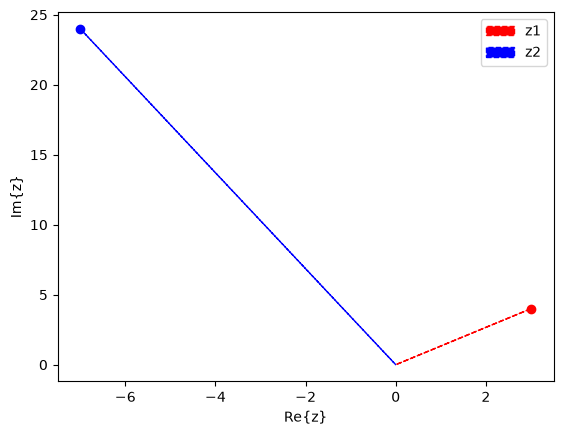

In [51]:
# Potencia dos numeros complexos
z2 = z1 ** 2

x1 = z1.real
y1 = z1.imag

x2 = z2.real
y2 = z2.imag


# Plot
fig, ax = plt.subplots()
ax.plot(x1, y1, 'ro')
ax.arrow(0, 0, x1, y1, color='r', linestyle='--', label='z1')
ax.plot(x2, y2, 'bo')
ax.arrow(0, 0, x2, y2, color='b', linestyle='--', label='z2')
ax.set_xlabel('Re{z}')
ax.set_ylabel('Im{z}')
ax.legend()
# figureFormat(ax, fig, tight=True)
plt.show()

In [52]:
# |z1^2| = |z1|^2  e  fase(z1^2) = 2 fase(z1)
print(f"|z1| = {myMagnitude(z1):.4f}   fase(z1) = {myPhase(z1, True):.4f}°")
print(f"|z2| = {myMagnitude(z2):.4f}  fase(z2) = {myPhase(z2, True):.4f}°  "
      f"(= 2 x {myPhase(z1, True):.4f}° = {2*myPhase(z1, True):.4f}°)")

|z1| = 5.0000   fase(z1) = 53.1301°
|z2| = 25.0000  fase(z2) = 106.2602°  (= 2 x 53.1301° = 106.2602°)


Elevar ao quadrado **eleva o módulo ao quadrado e dobra a fase**: $z^2 = r^2 e^{j2\theta}$.
Multiplicar complexos é escalar e girar — é por isso que eles servem para representar sinais oscilatórios.

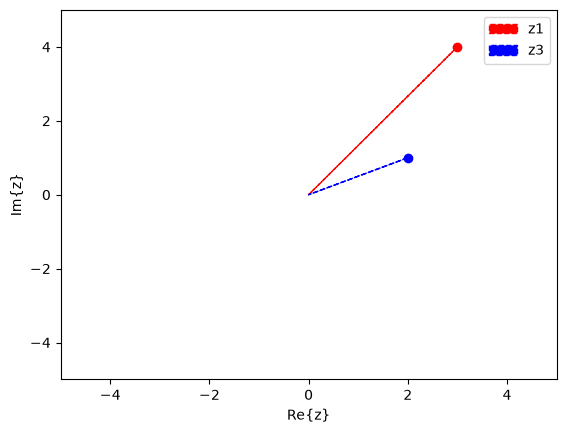

In [53]:
# Raiz dos numeros complexos
z3 = z1 ** 0.5 # raiz principal: |z3| = sqrt(|z1|), fase(z3) = fase(z1) / 2

x1, y1 = z1.real, z1.imag
x3, y3 = z3.real, z3.imag

# Plot
fig, ax = plt.subplots()
ax.plot(x1, y1, 'ro')
ax.arrow(0, 0, x1, y1, color='r', linestyle='--', label='z1')
ax.plot(x3, y3, 'bo')
ax.arrow(0, 0, x3, y3, color='b', linestyle='--', label='z3')
ax.set_xlabel('Re{z}')
ax.set_ylabel('Im{z}')
ax.legend()
ax.set_xlim([-5, 5])
ax.set_ylim([-5, 5])
plt.show()

In [54]:
print(f"|z3| = {myMagnitude(z3):.4f} (= sqrt(5))   fase(z3) = {myPhase(z3, True):.4f}° (= {myPhase(z1, True):.4f}° / 2)")

|z3| = 2.2361 (= sqrt(5))   fase(z3) = 26.5651° (= 53.1301° / 2)


### Mas a raiz quadrada tem **duas** respostas

`z1 ** 0.5` devolve só a raiz principal. Como a fase só é definida a menos de $2\pi$,
$z = r e^{j(\theta + 2\pi k)}$, as raízes $n$-ésimas são

$$
z^{1/n} = r^{1/n}\, e^{j\frac{\theta + 2\pi k}{n}}, \quad k = 0, 1, \dots, n-1
$$

$n$ pontos sobre um círculo de raio $r^{1/n}$, igualmente espaçados de $\frac{2\pi}{n}$: um polígono regular.
Para $n = 2$, a segunda raiz é $-z_3$.

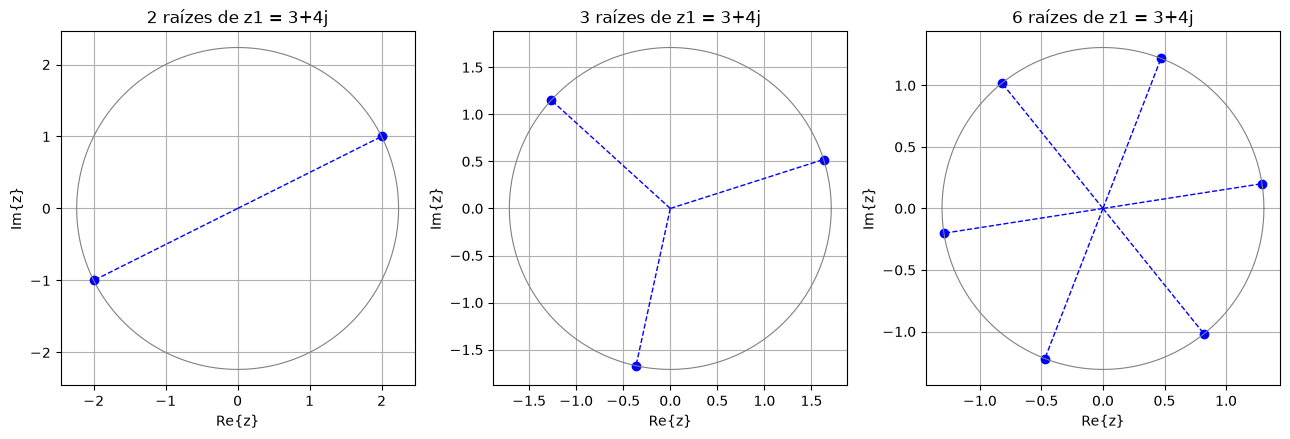

raizes quadradas: [(2+1j), (-2-1j)]


In [55]:
def myRoots(z, n):
    'as n raizes n-esimas de z (modulo e fase pelas funcoes proprias)'
    r, theta = myMagnitude(z), myPhase(z)
    return [r ** (1/n) * np.exp(1j * (theta + 2*MY_PI*k) / n) for k in range(n)]

fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, n in zip(axs, [2, 3, 6]):
    roots = myRoots(z1, n)
    for w in roots:
        assert abs(w**n - z1) < 1e-9 # cada uma, elevada a n, volta a z1
        ax.plot(w.real, w.imag, 'bo')
        ax.plot([0, w.real], [0, w.imag], 'b--', linewidth=1)
    t = np.linspace(0, 2*MY_PI, 200)
    R = myMagnitude(z1) ** (1/n)
    ax.plot(R*np.cos(t), R*np.sin(t), color='gray', linewidth=0.8)
    ax.set_title(f'{n} raízes de z1 = 3+4j')
    ax.set_xlabel('Re{z}')
    ax.set_ylabel('Im{z}')
    ax.set_aspect('equal')
    ax.grid(True)
fig.tight_layout()
plt.show()

print("raizes quadradas:", [complex(round(w.real, 6), round(w.imag, 6)) for w in myRoots(z1, 2)])

## # Curioso, não é?
Desafio: Antecipar o gráfico do seguinte número no plano complexo

In [56]:
z = 1j ** 1j

**Antecipação.** Na forma polar, $j = e^{j\pi/2}$. Então

$$
j^{\,j} = \left(e^{j\pi/2}\right)^{j} = e^{j \cdot j\pi/2} = e^{-\pi/2} \approx 0.2079
$$

Um número **real** e positivo: o ponto cai sobre o eixo $\mathrm{Re}\{z\}$, com fase zero.

Em geral $z^w = e^{w \ln z}$ com $\ln z = \ln|z| + j\,\mathrm{fase}(z)$. Para $z = j$: $|j| = 1$, então
$\ln j = j\,\mathrm{fase}(j)$ e $j^{\,j} = e^{-\mathrm{fase}(j)}$ — basta a nossa `myPhase`.

In [57]:
# Antecipacao com as funcoes proprias, antes de olhar o que o Python calcula
previsto = np.e ** (-myPhase(1j))
print(f"previsto: e^(-fase(j)) = e^(-{myPhase(1j):.6f}) = {previsto}")

previsto: e^(-fase(j)) = e^(-1.570796) = 0.20787957635076185


Python : (0.20787957635076193+0j)
e^(-pi/2) = 0.20787957635076193


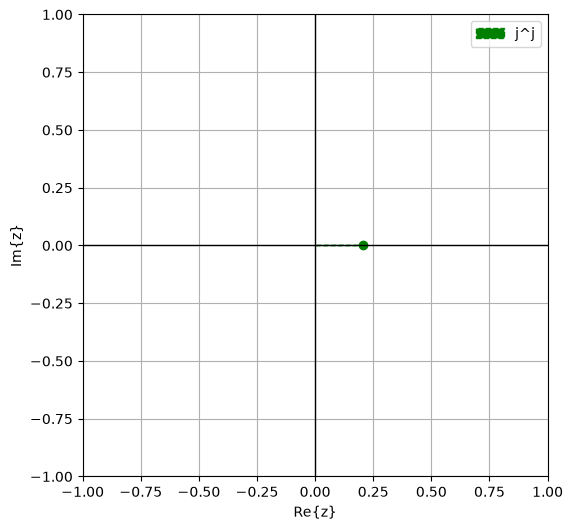

In [58]:
print(f"Python : {z}")
print(f"e^(-pi/2) = {np.exp(-np.pi/2)}")

x, y = z.real, z.imag

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x, y, 'go')
ax.arrow(0, 0, x, y, color='g', linestyle='--', label='j^j')
ax.axhline(0, color='black', linewidth=1)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Re{z}')
ax.set_ylabel('Im{z}')
ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.grid(True)
ax.legend()
plt.show()

### Mais curioso ainda: $j^{\,j}$ tem infinitos valores

A fase de $j$ não é só $\frac{\pi}{2}$: é $\frac{\pi}{2} + 2\pi k$ para qualquer inteiro $k$. Cada escolha dá um
valor diferente, **todos reais e positivos**:

$$
j^{\,j} = e^{-\left(\frac{\pi}{2} + 2\pi k\right)}, \quad k \in \mathbb{Z}
$$

O Python devolve o **ramo principal** ($k = 0$). Os outros caem todos sobre o semieixo real positivo,
em progressão geométrica de razão $e^{2\pi} \approx 535$.

k = -2:  j^j = 5.960974e+04
k = -1:  j^j = 1.113178e+02
k = +0:  j^j = 2.078796e-01   <- ramo principal (Python)
k = +1:  j^j = 3.882032e-04
k = +2:  j^j = 7.249473e-07


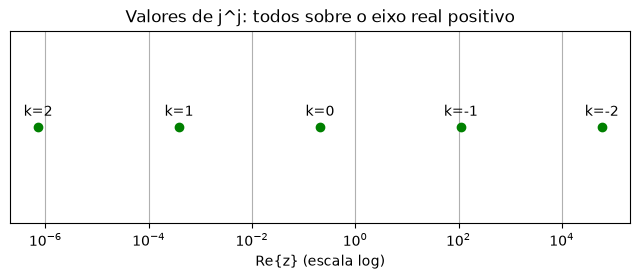

In [59]:
ks = np.arange(-2, 3)
valores = np.e ** (-(MY_PI/2 + 2*MY_PI*ks))
for k, v in zip(ks, valores):
    print(f"k = {k:+d}:  j^j = {v:.6e}" + ("   <- ramo principal (Python)" if k == 0 else ""))

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(valores, np.zeros_like(valores), 'go')
for k, v in zip(ks, valores):
    ax.annotate(f'k={k}', (v, 0), textcoords='offset points', xytext=(0, 8), ha='center')
ax.set_xscale('log')
ax.set_yticks([])
ax.set_xlabel('Re{z} (escala log)')
ax.set_title('Valores de j^j: todos sobre o eixo real positivo')
ax.grid(True)
plt.show()

## Sinais periodicos e nao periodicos

Um sinal discreto $x[n] = \cos(\omega n + \phi)$ só é periódico se a frequência digital for
uma fração racional de $2\pi$:

$$
\omega = 2\pi \frac{K_1}{K_2}, \quad K_1, K_2 \in \mathbb{Z} \quad \Rightarrow \quad x[n + K_2] = x[n]
$$

Com $K_1 = 1$ e $K_2 = 10$ o sinal se repete a cada 10 amostras.

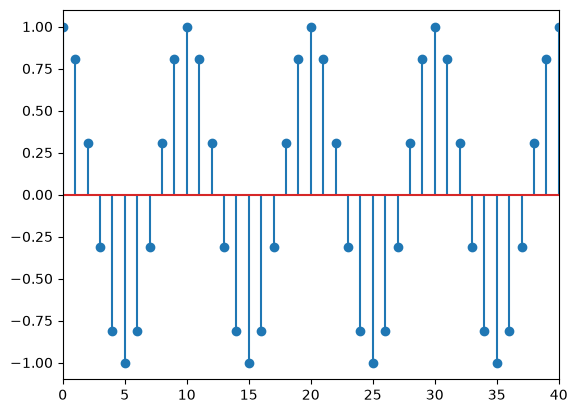

In [60]:
N = 100 # numero de amostras
n = np.arange(N)
K1 = 1
K2 = 10
omega = 2*np.pi * (K1 / K2) # freq. digital
phase = 0 # fase

x = np.cos(omega*n + phase)

fig, ax = plt.subplots()
ax.stem(n, x)
ax.set_xlim([0, 40])
plt.show()

Agora $\omega = 1$ rad/amostra: $\frac{2\pi}{\omega} = 2\pi$ é irracional, não existe inteiro $P$ com
$\omega P = 2\pi k$, e o sinal **nunca** se repete exatamente, embora a envoltória contínua $\cos(t)$ seja periódica.

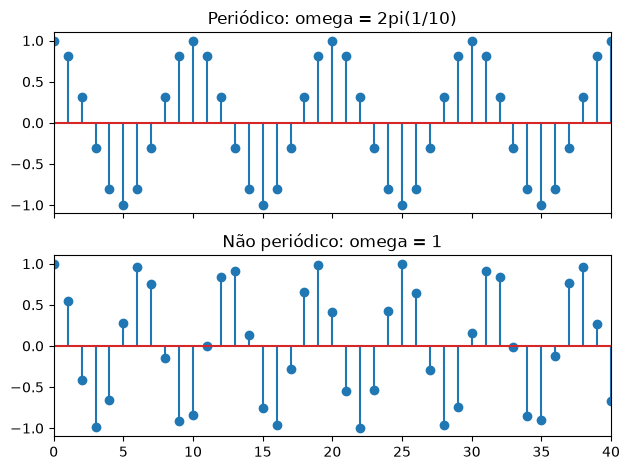

x (omega = 2pi/10): periodo fundamental P = 10
x2 (omega = 1): algum P < 50? False


In [61]:
omega2 = 1.0 # rad/amostra -> 2*pi/omega2 irracional
x2 = np.cos(omega2*n + phase)

fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].stem(n, x)
ax[0].set_title(f'Periódico: omega = 2pi({K1}/{K2})')
ax[1].stem(n, x2)
ax[1].set_title('Não periódico: omega = 1')
ax[1].set_xlim([0, 40])
fig.tight_layout()
plt.show()

# Verificacao numerica: x[n + P] == x[n] ?
for P in range(1, 50):
    if np.allclose(x[P:], x[:-P]):
        print(f"x (omega = 2pi/10): periodo fundamental P = {P}")
        break
print("x2 (omega = 1): algum P < 50?", any(np.allclose(x2[P:], x2[:-P]) for P in range(1, 50)))